In [3]:
"""
Inference & Representation - 2026 PS1
Question 2 PCA and Non-negative matrix factorization.

"""

"""
Tools for loading the MNIST Data.
From Optimization Based Data Analysis HW1
@author: Brett
"""
import numpy as np
from mnist_tools import *
from plot_tools import *
import matplotlib.pyplot as plt

"""
Given train (in the format returned by load_train_data in mnist_tools),
and a 1d numpy array testImage you should return a tuple (digit,imageIdx).  digit is
an integer giving the numerical digit value of the training image closest
to the testImage in Euclidean distance.  imageIdx is the row number of the closest
training image in the 2d array train[digit].
"""

"""
Assumes the data file is in 'mnist_all.mat'.
"""

datafile = "mnist_all.mat" #Change if you put the file in a different path
train = load_train_data(datafile)

trainarr=np.asarray(train)
trainarr = np.reshape(trainarr, (trainarr.shape[0]*trainarr.shape[1],-1))
trainarr = trainarr.astype(float)
trainarr=trainarr-trainarr.mean(axis=0)


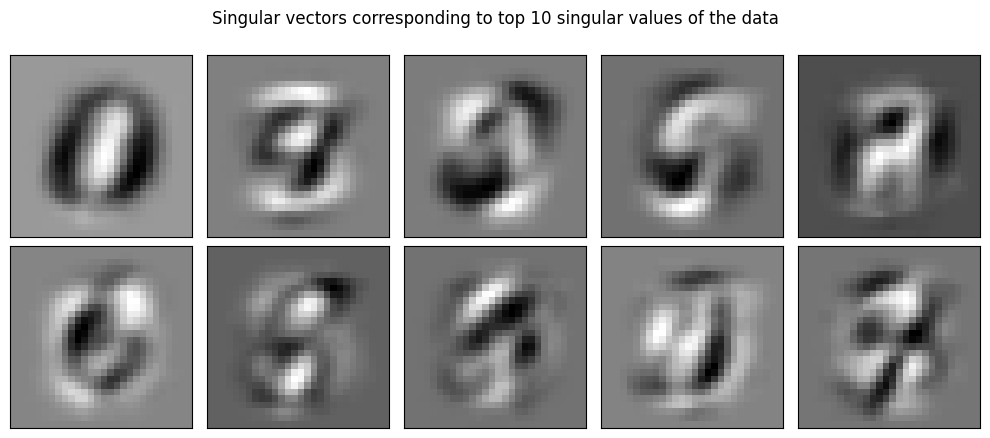

In [4]:
"""
Plot of the singular vectors corresponding
to top 10 singular values of the data.
@author: Vlad
"""
U, s, V = np.linalg.svd(trainarr, full_matrices=True)
n=10
imgs = [V[i,:] for i in range(n)]
plot_image_grid(imgs,
           "Singular vectors corresponding to top 10 singular values of the data")


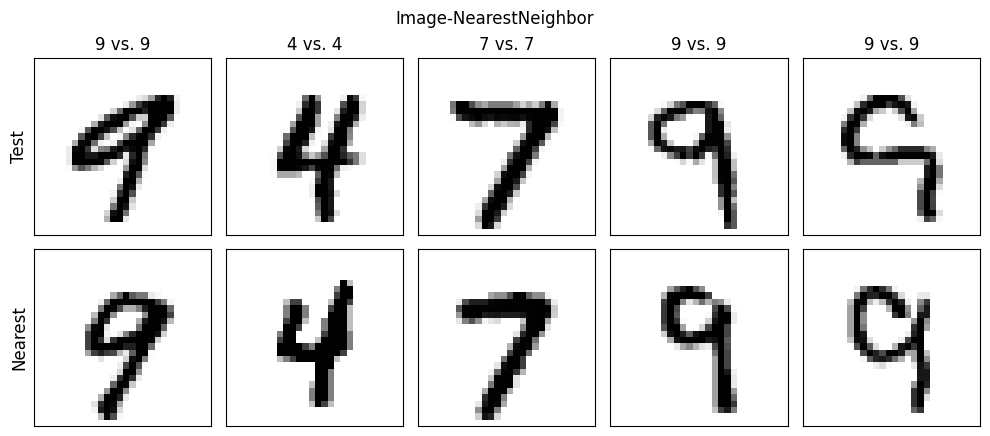

In [5]:
"""
Plot of the results of the nearest neighbour test applied
to a principal component projection.
@author: Vlad
"""

def project(V, Images) :
     return np.dot(V.T, np.dot(V, Images))

def compute_nearest_neighbors(train, testImage, V) :
    train=[np.array(i, dtype=float) for i in train]
    testImage= np.array(testImage, dtype=float)
    digit=0
    imageIdx=0
    dist=np.linalg.norm (project (V, train[digit][imageIdx])-project (V, testImage))
    for i in range(len(train)):
        for j in range (train[i].shape[0]):
            tempDist=np.linalg.norm (project(V,train[i][j])-project(V, testImage))
            if tempDist<dist:
                digit=i
                imageIdx =j
                dist= tempDist
    return digit, imageIdx

n=8
U, s, V = np.linalg.svd(trainarr, full_matrices=False)
V=V[0:n,:]


test,testLabels = load_test_data(datafile)


imgs = []
TestLabels = []
for i in range(len(testLabels)) :
    trueDigit = testLabels[i]
    testImage = test[i]
    (nnDig,nnIdx) = compute_nearest_neighbors(train,testImage,V)
    imgs.extend( [testImage,train[nnDig][nnIdx,:]] )
    TestLabels.append(nnDig)

row_titles = ['Test','Nearest']
col_titles = ['%d vs. %d'%(i,j) for i,j in zip(testLabels,testLabels)]
plot_image_grid(imgs,
                    "Image-NearestNeighbor",
                    (28,28),len(testLabels),2,True,row_titles=row_titles,col_titles=col_titles)


***

## Problem 2-Part (a).

For Part 2(a), the sequence should be roughly:
1. Reconstruct a clean nonnegative data matrix \(X\) from the existing train variable, without modifying our earlier PCA code.
2. Initialize \(W\) and \(H\) for one value of \(r\), starting with \(r=3\).
3. Implement the NMF multiplicative updates from Problem 1.
4. Run the algorithm and check that it behaves sensibly.
5. Plot the rows of \(H\).
6. Once that works, run the same setup for \(r=6\) and \(r=10\).

In [6]:
# Question 2(a): Create a nonnegative data matrix for NMF

X_nmf = np.asarray(train, dtype=float)

# Reshape from (10, 100, 784) to (1000, 784)
X_nmf = np.reshape(
    X_nmf,
    (X_nmf.shape[0] * X_nmf.shape[1], -1)
)

print("Shape of X_nmf:", X_nmf.shape)
print("Minimum value:", X_nmf.min())
print("Maximum value:", X_nmf.max())

Shape of X_nmf: (1000, 784)
Minimum value: 0.0
Maximum value: 255.0


In [7]:
# Start with r = 3 latent components
r = 3

# Random positive initialization
np.random.seed(0)

W = np.random.rand(X_nmf.shape[0], r)
H = np.random.rand(r, X_nmf.shape[1])

print("W shape:", W.shape)
print("H shape:", H.shape)

W shape: (1000, 3)
H shape: (3, 784)


In [8]:
# NMF with random positive initialization
def run_nmf(X, r, num_iters=200, seed=0, eps=1e-10):
    np.random.seed(seed)

    # Initialize W and H with positive values
    W = np.random.rand(X.shape[0], r)
    H = np.random.rand(r, X.shape[1])

    # Multiplicative updates
    for _ in range(num_iters):
        WH = W @ H

        # Update W
        W *= ((X / (WH + eps)) @ H.T) / (
            np.ones_like(X) @ H.T + eps
        )

        WH = W @ H

        # Update H
        H *= (W.T @ (X / (WH + eps))) / (
            W.T @ np.ones_like(X) + eps
        )

    return W, H

In [9]:
# Test cell
W3, H3 = run_nmf(X_nmf, r=3)

print(W3.shape)
print(H3.shape)

(1000, 3)
(3, 784)


In [10]:
# Run NMF for all required values of r
r_values = [3, 6, 10]

nmf_results = {}

for r in r_values:
    W, H = run_nmf(X_nmf, r=r)
    nmf_results[r] = (W, H)

    print(f"r = {r}: W shape = {W.shape}, H shape = {H.shape}")

r = 3: W shape = (1000, 3), H shape = (3, 784)
r = 6: W shape = (1000, 6), H shape = (6, 784)
r = 10: W shape = (1000, 10), H shape = (10, 784)


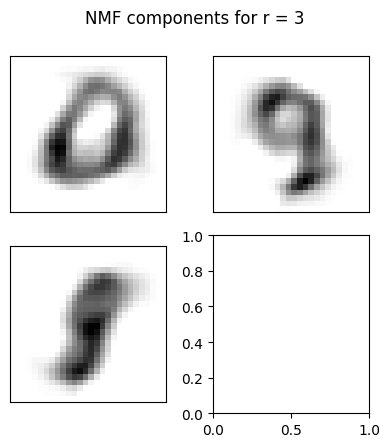

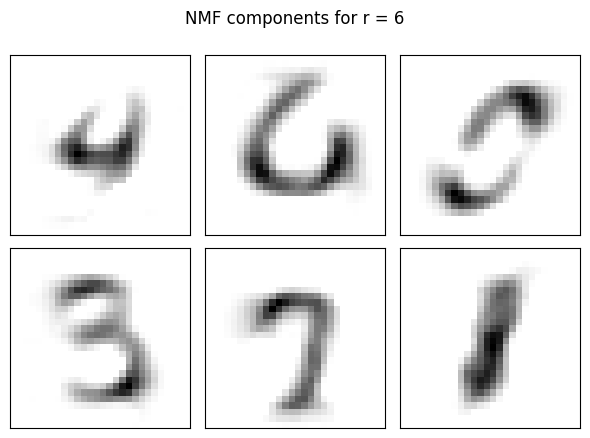

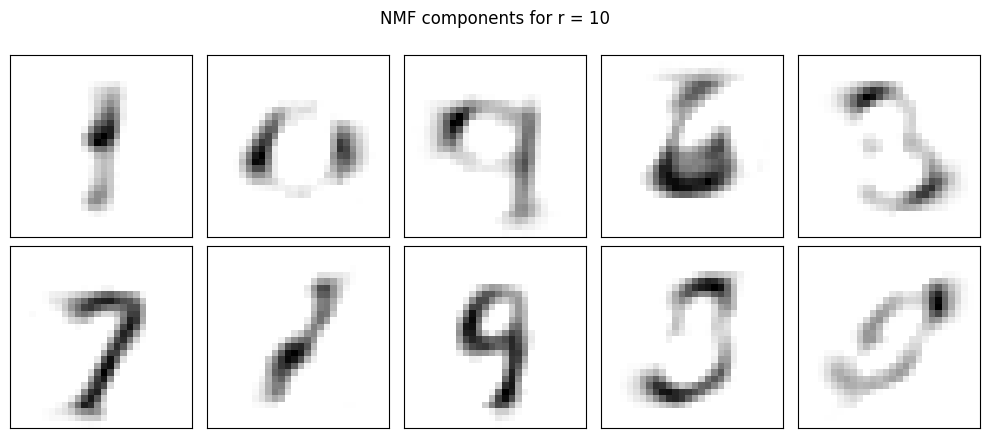

In [11]:
# Plot the learned NMF components for each value of r
for r in r_values:
    W, H = nmf_results[r]

    if r == 3:
        n_row, n_col = 2, 2   # one empty panel
    elif r == 6:
        n_row, n_col = 2, 3
    else:  # r == 10
        n_row, n_col = 2, 5

    plot_image_grid(
        [H[i, :] for i in range(r)],
        f"NMF components for r = {r}",
        n_col=n_col,
        n_row=n_row
    )

***

# Problem 2 - Part b



First, we write a small function that takes images and \(H\), and returns their \(r\)-dimensional coefficients.

In [37]:
# Compute nonnegative coefficients of images using a fixed NMF basis H
def nmf_project(images, H, num_iters=200, seed=0, eps=1e-10):

    np.random.seed(seed)

    # Number of images and number of latent components
    n_images = images.shape[0]
    r = H.shape[0]

    # Initialize the coefficients with positive values
    coefficients = np.random.rand(n_images, r)

    # Update only the coefficients; H stays fixed
    for _ in range(num_iters):
        reconstruction = coefficients @ H

        coefficients *= (
            (images / (reconstruction + eps)) @ H.T
        ) / (
            np.ones_like(images) @ H.T + eps
        )

    return coefficients

In [46]:
# Test the learned training coefficients for r = 3
W3, H3 = nmf_results[3]

train_coeffs_3 = W3

print("Projected training shape:", train_coeffs_3.shape)
print("Minimum coefficient:", train_coeffs_3.min())
print("Maximum coefficient:", train_coeffs_3.max())

Projected training shape: (1000, 3)
Minimum coefficient: 1.3724211779095248e-116
Maximum coefficient: 139.22841782526064


In [39]:
print("First image coefficients:", train_coeffs_3[0])

First image coefficients: [8.14285335e+01 1.43630096e+00 1.68846837e-11]


Load and prepare the test images.

In [47]:
# Load the test images and their true digit labels
test, testLabels = load_test_data(datafile)

# Convert the test images to a floating-point NumPy array
test_nmf = np.asarray(test, dtype=float)

print("Test data shape:", test_nmf.shape)
print("Test labels:", testLabels)
print("Minimum pixel value:", test_nmf.min())

Test data shape: (5, 784)
Test labels: [9, 4, 7, 9, 9]
Minimum pixel value: 0.0


Project both training and test images into the \(r\)-dimensional space.

In [48]:
# Project training and test images into each NMF latent space

projected_data = {}

for r in r_values:
    W, H = nmf_results[r]

    # Training coefficients are already learned in W
    train_coeffs = W

    # Infer nonnegative coefficients for the test images
    test_coeffs = nmf_project(test_nmf, H)

    # Save them for nearest-neighbor comparison
    projected_data[r] = (train_coeffs, test_coeffs)

    print(
        f"r = {r}: "
        f"train shape = {train_coeffs.shape}, "
        f"test shape = {test_coeffs.shape}"
    )

r = 3: train shape = (1000, 3), test shape = (5, 3)
r = 6: train shape = (1000, 6), test shape = (5, 6)
r = 10: train shape = (1000, 10), test shape = (5, 10)


Nearest neighbor in the NMF coefficient space.

In [49]:
def nearest_neighbor_nmf(train_coeffs, test_coeff, r):
    # Make sure the latent-space dimension matches r
    assert train_coeffs.shape[1] == r
    assert test_coeff.shape[0] == r

    # Compute Euclidean distance to every training image
    distances = np.linalg.norm(train_coeffs - test_coeff, axis=1)

    # Find the closest training image
    nearest_idx = np.argmin(distances)

    # Convert flat index back to digit class and image index
    digit = nearest_idx // 100
    image_idx = nearest_idx % 100

    return digit, image_idx

In [50]:
# This is a test to check whether our function above works well.
train_coeffs_3, test_coeffs_3 = projected_data[3]

digit, image_idx = nearest_neighbor_nmf(
    train_coeffs_3,
    test_coeffs_3[0],
    r=3
)

print("True digit:", testLabels[0])
print("Predicted digit:", digit)
print("Nearest image index:", image_idx)

True digit: 9
Predicted digit: 8
Nearest image index: 2


In [51]:
# Two more tests to make sure our function works well and correct.
for r in [6, 10]:
    train_coeffs, test_coeffs = projected_data[r]

    digit, image_idx = nearest_neighbor_nmf(
        train_coeffs,
        test_coeffs[0],
        r=r
    )

    print(f"r = {r}")
    print("True digit:", testLabels[0])
    print("Predicted digit:", digit)
    print("Nearest image index:", image_idx)
    print()

r = 6
True digit: 9
Predicted digit: 9
Nearest image index: 47

r = 10
True digit: 9
Predicted digit: 9
Nearest image index: 47



Evaluate nearest-neighbor predictions for all test images

In [52]:
# Evaluate nearest-neighbor predictions for all test images
# for each NMF latent dimension r

for r in r_values:
    train_coeffs, test_coeffs = projected_data[r]

    correct = 0

    print(f"Results for r = {r}")

    for i in range(len(testLabels)):
        digit, image_idx = nearest_neighbor_nmf(
            train_coeffs,
            test_coeffs[i],
            r=r
        )

        true_digit = testLabels[i]

        print(
            f"Test {i}: true = {true_digit}, "
            f"predicted = {digit}, "
            f"nearest image index = {image_idx}"
        )

        if digit == true_digit:
            correct += 1

    print(f"Correct predictions: {correct}/{len(testLabels)}")
    print()

Results for r = 3
Test 0: true = 9, predicted = 8, nearest image index = 2
Test 1: true = 4, predicted = 2, nearest image index = 21
Test 2: true = 7, predicted = 7, nearest image index = 72
Test 3: true = 9, predicted = 9, nearest image index = 23
Test 4: true = 9, predicted = 9, nearest image index = 82
Correct predictions: 3/5

Results for r = 6
Test 0: true = 9, predicted = 9, nearest image index = 47
Test 1: true = 4, predicted = 4, nearest image index = 14
Test 2: true = 7, predicted = 7, nearest image index = 92
Test 3: true = 9, predicted = 9, nearest image index = 42
Test 4: true = 9, predicted = 5, nearest image index = 45
Correct predictions: 4/5

Results for r = 10
Test 0: true = 9, predicted = 9, nearest image index = 47
Test 1: true = 4, predicted = 9, nearest image index = 12
Test 2: true = 7, predicted = 7, nearest image index = 11
Test 3: true = 9, predicted = 9, nearest image index = 42
Test 4: true = 9, predicted = 9, nearest image index = 52
Correct predictions: 4/5

Collect test images and their nearest neighbors

In [53]:
# Use the r = 6 NMF representation
r = 6
train_coeffs, test_coeffs = projected_data[r]

imgs = []
predicted_labels = []

for i in range(len(testLabels)):

    # Find nearest training image in the NMF latent space
    digit, image_idx = nearest_neighbor_nmf(
        train_coeffs,
        test_coeffs[i],
        r=r
    )

    # Add the test image and its nearest training image
    imgs.extend([
        test_nmf[i],
        train[digit][image_idx, :]
    ])

    predicted_labels.append(digit)

print("True labels:", testLabels)
print("Predicted labels:", predicted_labels)

True labels: [9, 4, 7, 9, 9]
Predicted labels: [np.int64(9), np.int64(4), np.int64(7), np.int64(9), np.int64(5)]


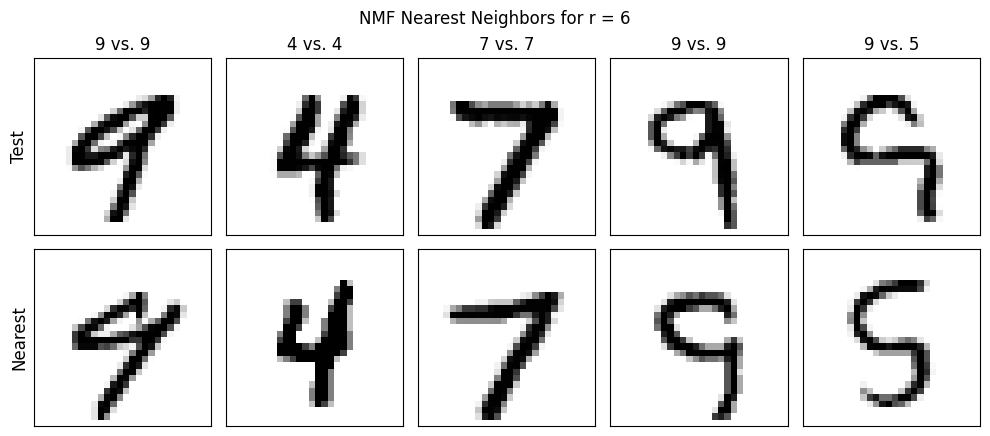

In [54]:
# Plot each test image next to its nearest training image for r = 6

row_titles = ['Test', 'Nearest']

col_titles = [
    f'{true} vs. {pred}'
    for true, pred in zip(testLabels, predicted_labels)
]

plot_image_grid(
    imgs,
    "NMF Nearest Neighbors for r = 6",
    (28, 28),
    len(testLabels),
    2,
    True,
    row_titles=row_titles,
    col_titles=col_titles
)

Among r in {3,6,10}, both r=6 and r=10 correctly classified 4 out of 5 test images using nearest neighbors in the NMF latent space. Since r=6 achieved the same performance with a lower-dimensional representation, we selected r=6.

## Problem 2 - Part C

Choose one random training image from each digit.

In [28]:
# Select one random training image from each digit class

np.random.seed(1)  # makes the random choice reproducible

random_images = []
random_indices = []

for digit in range(10):
    # Choose one random image index from the 100 images of this digit
    idx = np.random.randint(0, train[digit].shape[0])

    random_images.append(train[digit][idx, :])
    random_indices.append(idx)

print("Chosen image indices:", random_indices)

Chosen image indices: [37, 12, 72, 9, 75, 5, 79, 64, 16, 1]


In [30]:
# Recompute PCA and keep the first 10 principal directions
U_pca, s_pca, V_pca = np.linalg.svd(trainarr, full_matrices=False)

V10 = V_pca[:10, :]

print("V10 shape:", V10.shape)

V10 shape: (10, 784)


In [31]:
# Stack the 10 selected images into one matrix
random_images_arr = np.asarray(random_images, dtype=float)

# Center using the same mean used for PCA
train_mean = np.asarray(train, dtype=float).reshape(-1, 784).mean(axis=0)
random_images_centered = random_images_arr - train_mean

# Project onto the first 10 PCA directions
pca_coeffs = random_images_centered @ V10.T

print("PCA coefficient matrix shape:", pca_coeffs.shape)

PCA coefficient matrix shape: (10, 10)


In [32]:
# Quick test for the PCA coefficients
# Inspect the first selected image (digit 0)
print("First image coefficient vector shape:", pca_coeffs[0].shape)
print("First image PCA coefficients:")
print(pca_coeffs[0])

First image coefficient vector shape: (10,)
First image PCA coefficients:
[ 974.47145757  -98.10436109  190.00725771  433.79754593  460.39921403
  559.0589848   -87.41000592 -644.11628901 -117.00390928 -282.24641971]


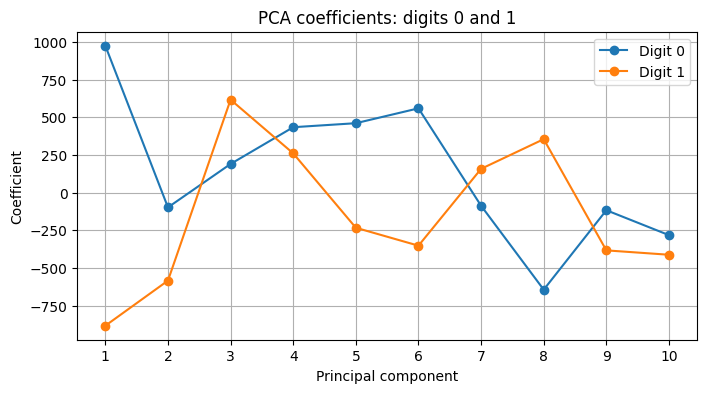

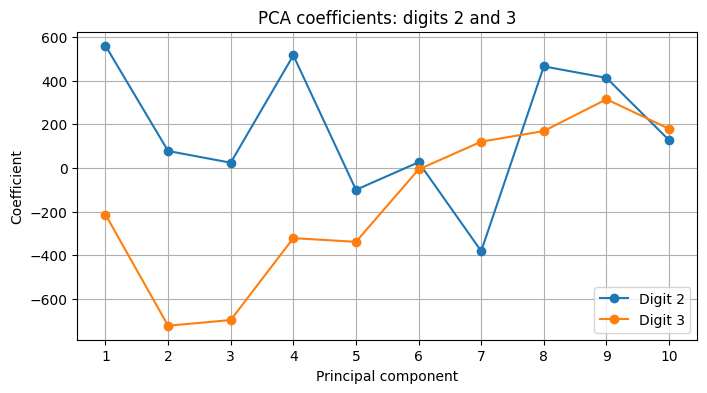

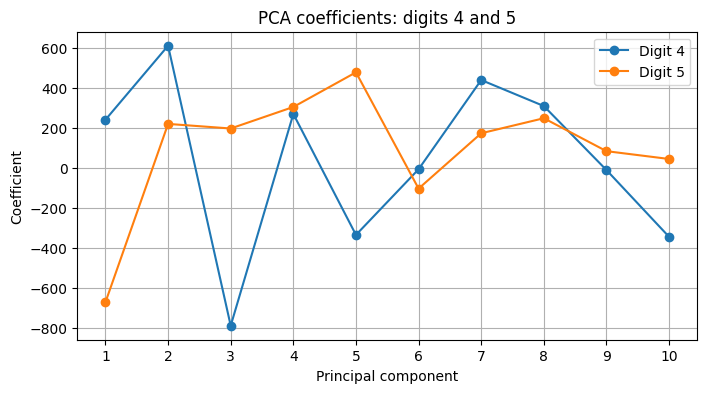

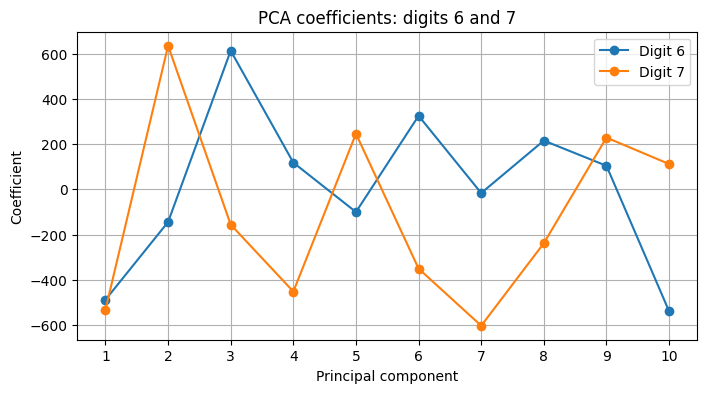

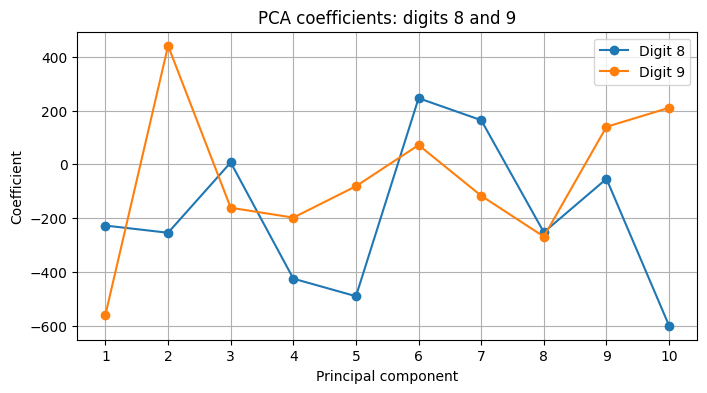

In [34]:
# Plot PCA coefficients in 5 smaller plots, with 2 digits per plot

digit_pairs = [
    (0, 1),
    (2, 3),
    (4, 5),
    (6, 7),
    (8, 9)
]

for d1, d2 in digit_pairs:
    plt.figure(figsize=(8, 4))

    # Plot the PCA coefficients for the first digit
    plt.plot(
        range(1, 11),
        pca_coeffs[d1],
        marker='o',
        label=f'Digit {d1}'
    )

    # Plot the PCA coefficients for the second digit
    plt.plot(
        range(1, 11),
        pca_coeffs[d2],
        marker='o',
        label=f'Digit {d2}'
    )

    plt.xlabel("Principal component")
    plt.ylabel("Coefficient")
    plt.title(f"PCA coefficients: digits {d1} and {d2}")
    plt.xticks(range(1, 11))
    plt.legend()
    plt.grid(True)
    plt.show()

Compute NMF coefficients for the same 10 image.

In [55]:
# Get the NMF model for r = 10
W10, H10 = nmf_results[10]

# Compute the 10 NMF coefficients for each selected image
nmf_coeffs = nmf_project(random_images_arr, H10)


print("NMF coefficient matrix shape:", nmf_coeffs.shape)

NMF coefficient matrix shape: (10, 10)


In [56]:
# Before plotting, I do want one quick sanity check because NMF coefficients should generally be nonnegative here.
# Sanity check for NMF coefficients
print("Minimum NMF coefficient:", nmf_coeffs.min())
print("Maximum NMF coefficient:", nmf_coeffs.max())
print("First image NMF coefficients:")
print(nmf_coeffs[0])

Minimum NMF coefficient: 3.150185138224113e-245
Maximum NMF coefficient: 55.460089990981594
First image NMF coefficients:
[2.42696721e-01 3.38074691e+01 5.06499219e-39 2.68098612e+01
 3.09936833e-16 4.11385118e-17 9.94243470e-16 6.73992258e-02
 1.10265596e+01 1.75890336e+00]


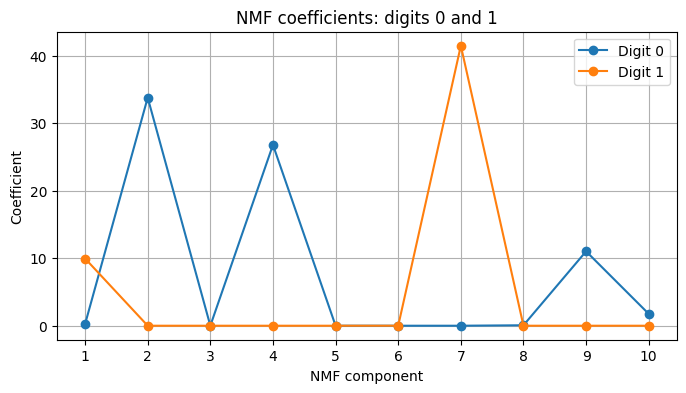

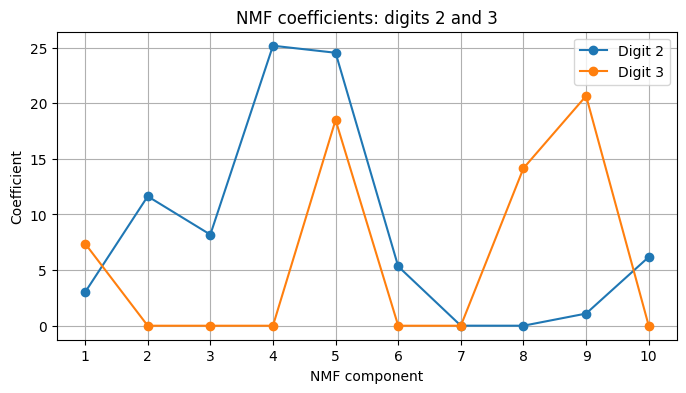

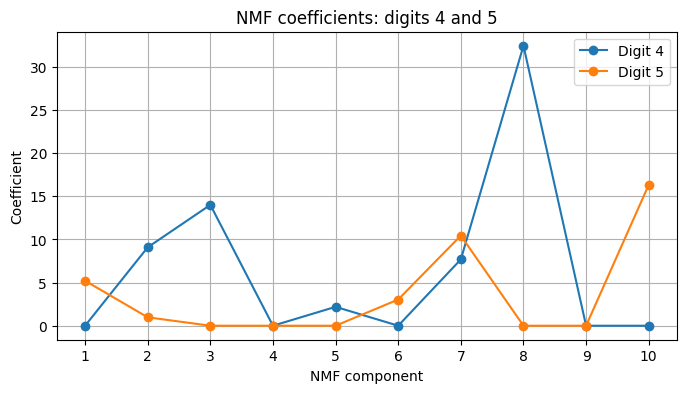

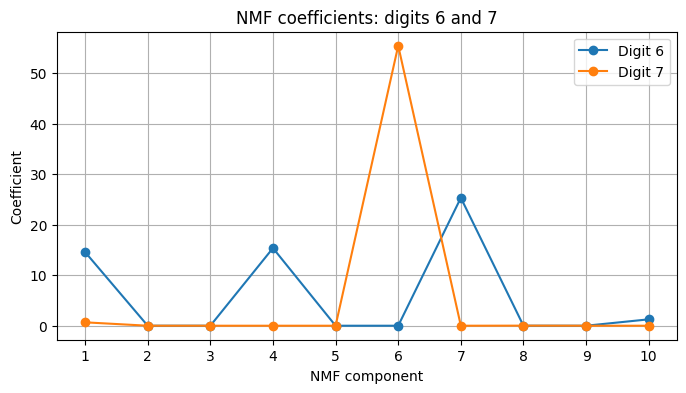

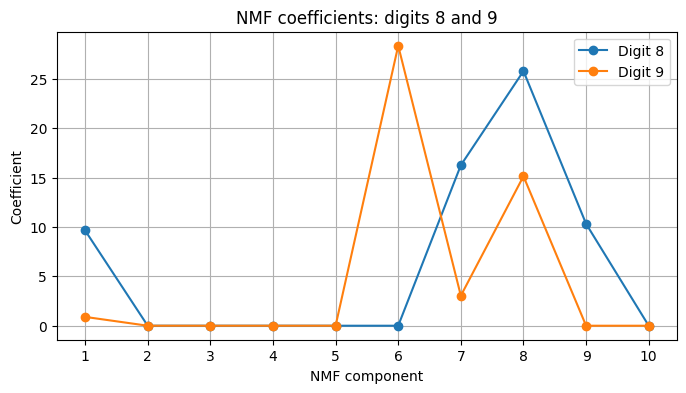

In [58]:
# Plot NMF coefficients in 5 smaller plots, with 2 digits per plot

digit_pairs = [
    (0, 1),
    (2, 3),
    (4, 5),
    (6, 7),
    (8, 9)
]

for d1, d2 in digit_pairs:
    plt.figure(figsize=(8, 4))

    # Plot NMF coefficients for the first digit
    plt.plot(
        range(1, 11),
        nmf_coeffs[d1],
        marker='o',
        label=f'Digit {d1}'
    )

    # Plot NMF coefficients for the second digit
    plt.plot(
        range(1, 11),
        nmf_coeffs[d2],
        marker='o',
        label=f'Digit {d2}'
    )

    plt.xlabel("NMF component")
    plt.ylabel("Coefficient")
    plt.title(f"NMF coefficients: digits {d1} and {d2}")
    plt.xticks(range(1, 11))
    plt.legend()
    plt.grid(True)
    plt.show()
